# 02 — Results Analysis

This notebook **does not retrain anything**. It loads the artifacts produced by `python src/train.py`
(the serialized model and the reports) and analyses them.

**Evaluation protocol** (implemented in `src/train.py`):
1. Stratified 80/20 split; the test set is used only once, for final reporting.
2. Hyperparameters tuned by 5-fold stratified cross-validation (CV) on the training set, optimizing ROC AUC.
3. The model is **selected by mean CV score**, never by test performance.
4. The decision threshold is chosen on **out-of-fold** predictions of the training set.
5. Test metrics are reported with 95% bootstrap confidence intervals.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import joblib
import pandas as pd
from IPython.display import Image, Markdown, display

from oncopredict.config import FIGURES_DIR, MODEL_PATH, REPORTS_DIR
from oncopredict.data import load_data, split_data
from oncopredict.evaluation import threshold_metrics
from oncopredict.models import MODEL_LABELS

artifact = joblib.load(MODEL_PATH)
X, y = load_data()
X_train, X_test, y_train, y_test = split_data(X, y)
proba = artifact["pipeline"].predict_proba(X_test)[:, 1]

print(f"Deployed model: {MODEL_LABELS[artifact['model_name']]}")
print(f"Threshold: {artifact['threshold']:.3f} ({artifact['threshold_rule']})")

Deployed model: Logistic Regression
Threshold: 0.216 (Sensitivity ≥ 98%)


## Model comparison

All three models reach a CV ROC AUC above 0.98. Logistic Regression has the highest mean CV score and is
selected. The test-set confidence intervals overlap almost completely, and the McNemar tests below find no
significant difference: with 114 test samples, the candidates are **statistically indistinguishable**.
Reporting this honestly is more valuable than declaring a winner based on one or two patients.

In [2]:
comparison = pd.read_csv(REPORTS_DIR / "model_comparison.csv")
comparison.assign(model=comparison.model.map(MODEL_LABELS)).round(4)

,model,cv_mean,cv_std,test_auc,test_auc_ci_low,test_auc_ci_high,test_brier,best_params
0,Logistic Regression,0.9959,0.0046,0.9960,0.9863,1.0,0.0211,"{'C': 1, 'solver': 'liblinear'}"
1,SVM,0.9949,0.0050,0.9947,0.9828,1.0,0.0222,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}"
2,Random Forest,0.9889,0.0067,0.9947,0.9855,1.0,0.0325,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est..."


In [3]:
report = (REPORTS_DIR / "final_report.md").read_text()
section = report.split("## Pairwise McNemar")[1].split("## Decision threshold")[0]
display(Markdown("### Pairwise McNemar" + section))

### Pairwise McNemar tests (test set, threshold 0.50)

| Comparison | A right, B wrong | A wrong, B right | p-value |
|---|---|---|---|
| Logistic Regression vs Random Forest | 3 | 2 | 1.000 |
| Logistic Regression vs SVM | 3 | 2 | 1.000 |
| Random Forest vs SVM | 3 | 3 | 1.000 |



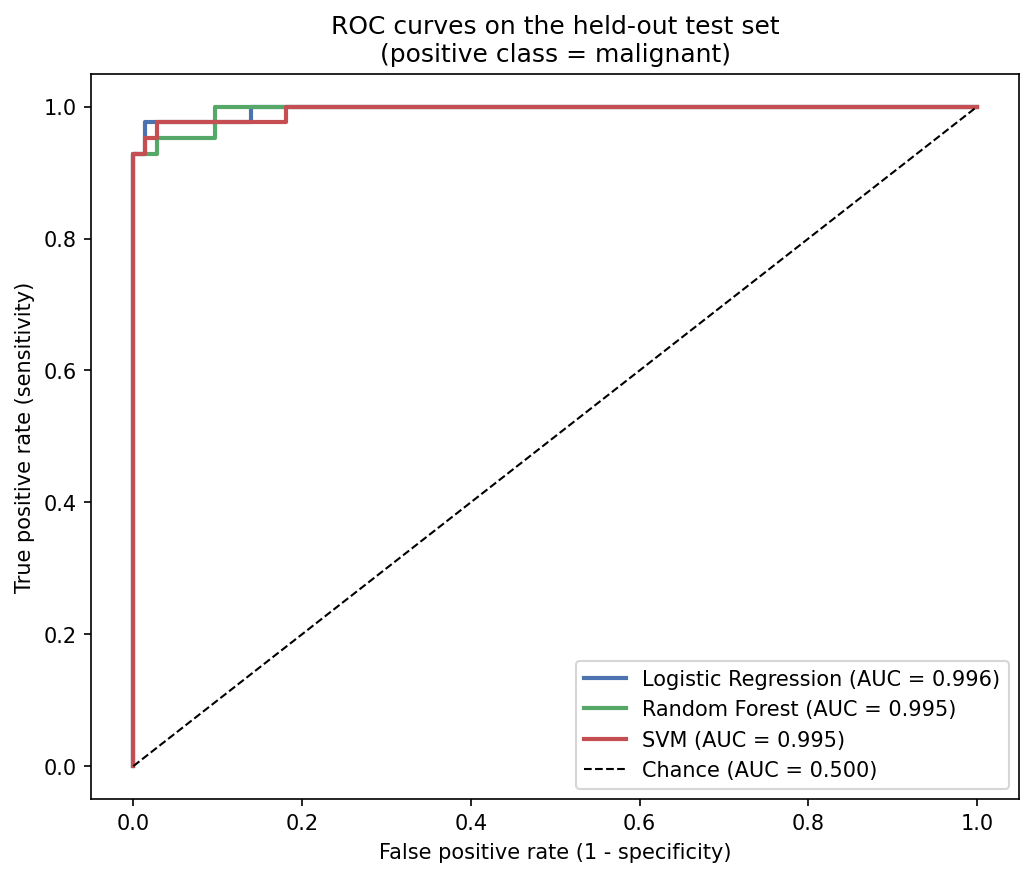

In [4]:
display(Image(FIGURES_DIR / "roc_curves.png", width=550))

## Choosing the decision threshold

A classifier outputs a probability; turning it into a decision requires a threshold. 0.5 is arbitrary.
In a cancer-screening context a **false negative** (a missed cancer) is far costlier than a **false
positive** (an unnecessary biopsy), so the deployed rule is: *the highest threshold that keeps
out-of-fold sensitivity ≥ 98%*.

Choosing the threshold on out-of-fold training predictions (left panel) and only then applying it to the
test set (right panels) keeps the test evaluation unbiased.

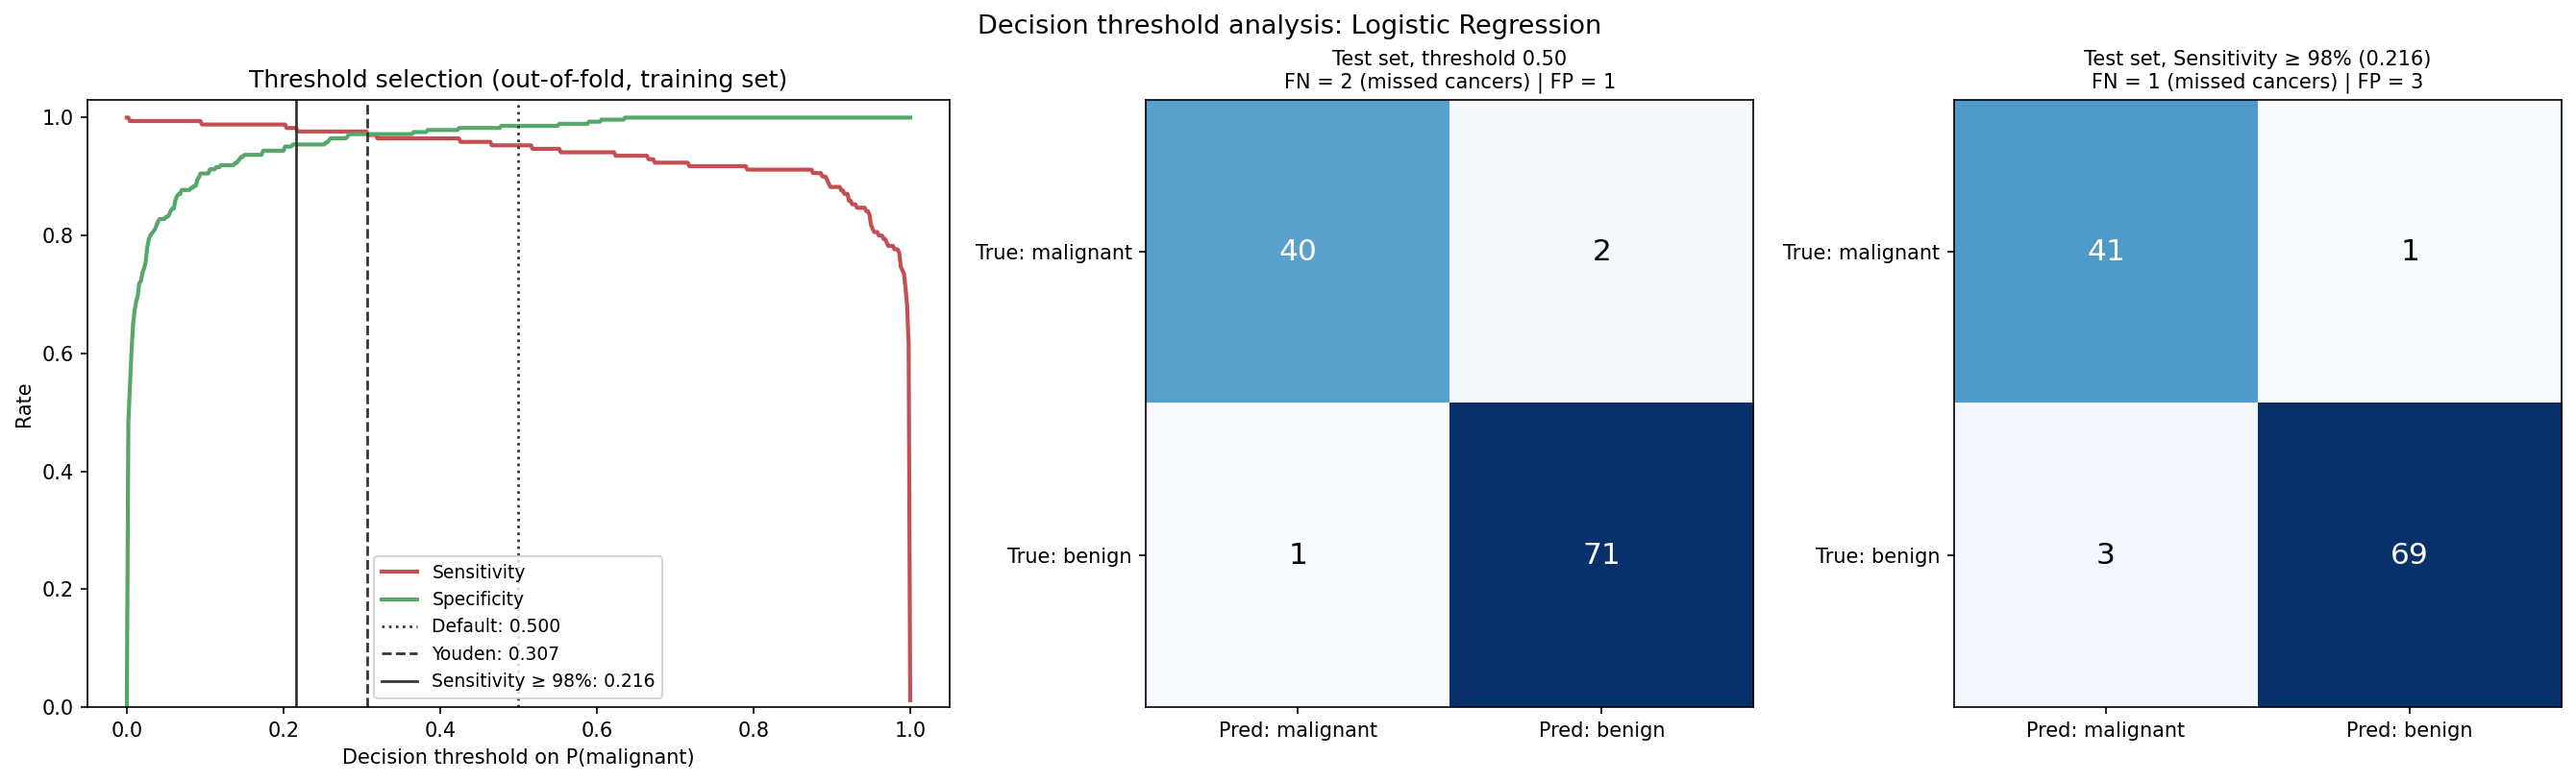

In [5]:
display(Image(FIGURES_DIR / "threshold_analysis.png"))

In [6]:
rows = {}
for t in [0.1, artifact["threshold"], 0.3, 0.5, 0.7]:
    m = threshold_metrics(y_test, proba, t)
    rows[f"{t:.3f}"] = {k: m[k] for k in ["fn", "fp", "sensitivity", "specificity", "ppv", "npv"]}
pd.DataFrame(rows).T.rename_axis("threshold").round(3)

,fn,fp,sensitivity,specificity,ppv,npv
threshold,,,,,,
0.100,1.0,5.0,0.976,0.931,0.891,0.985
0.216,1.0,3.0,0.976,0.958,0.932,0.986
0.300,1.0,1.0,0.976,0.986,0.976,0.986
0.500,2.0,1.0,0.952,0.986,0.976,0.973
0.700,4.0,0.0,0.905,1.000,1.000,0.947


Lowering the threshold from 0.50 to the deployed value trades two extra false alarms for one fewer missed
cancer on the test set, which is the intended direction.

On this particular test set, a threshold around 0.30 (close to the Youden threshold) would have done
slightly better (1 FN, 1 FP). This is only visible *after* looking at the test set. Switching to it
now would reintroduce exactly the bias the protocol avoids, so the pre-registered rule is kept.

The confidence intervals in
`reports/final_report.md` show that, with only 42 malignant test cases, sensitivity can only be pinned down
to within several percentage points.

## Calibration

*Calibration* asks whether predicted probabilities can be taken at face value: among tumors given 70%
risk, are about 70% malignant? It is a different property from discrimination (AUC). The **Brier score**
(mean squared error of the probabilities, lower is better) summarizes it. Logistic Regression and SVM lie
close to the diagonal; Random Forest is slightly under-confident in the middle range. With 114 samples the
5-bin curve is coarse, so this is a sanity check rather than a precise estimate.

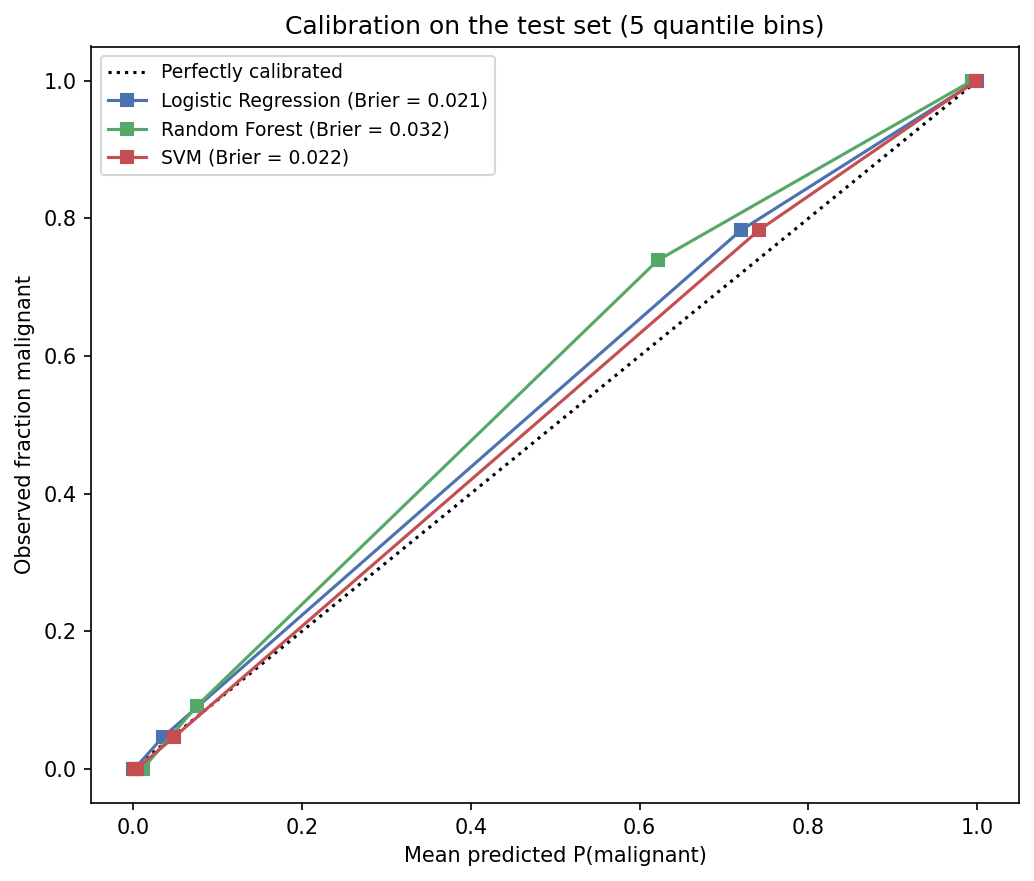

In [7]:
display(Image(FIGURES_DIR / "calibration.png", width=550))

## Decision curve analysis

Decision curve analysis (Vickers & Elkin, 2006) asks a clinical question: *is acting on the model better
than the default strategies "biopsy everyone" or "biopsy no one"?* The x-axis is the risk at which a
clinician would order a biopsy; the y-axis is the **net benefit**, i.e. true positives per patient minus
false positives weighted by how much the clinician fears them.

All models dominate both default strategies across the whole range of reasonable thresholds, so using any
of them would lead to better decisions than the defaults on this population.

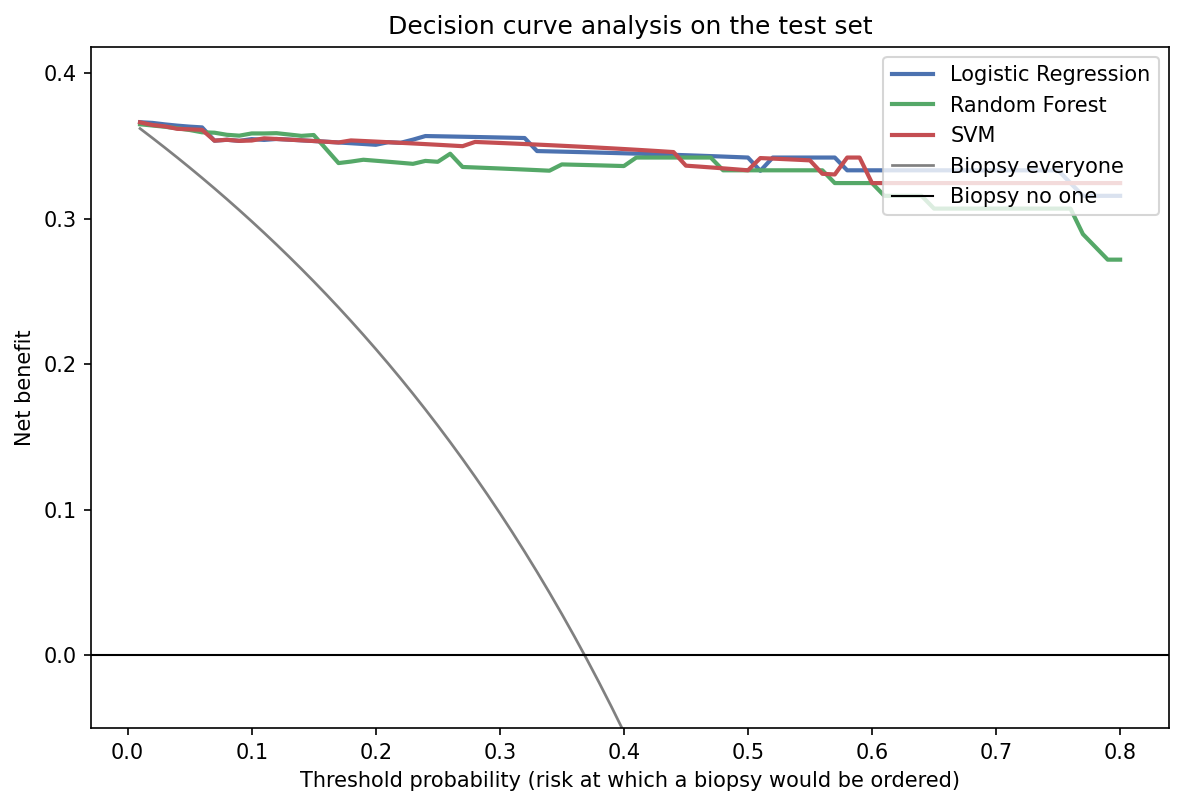

In [8]:
display(Image(FIGURES_DIR / "decision_curve.png", width=650))

## Error analysis

Aggregate metrics hide *which* patients the model gets wrong. Below are the test cases misclassified at the
deployed threshold, together with how far their key measurements are from the typical (median) training
case of each class.

In [9]:
pred = (proba >= artifact["threshold"]).astype(int)
errors = X_test.assign(true=y_test, p_malignant=proba.round(3))[pred != y_test.to_numpy()]
errors["error"] = errors.true.map({1: "false negative (missed cancer)", 0: "false positive"})

key = ["worst concave points", "worst perimeter", "worst texture", "mean concave points"]
medians = X_train.groupby(y_train)[key].median().rename(index={0: "median benign", 1: "median malignant"})
display(errors[["error", "p_malignant"] + key])
display(medians.round(3))

,error,p_malignant,worst concave points,worst perimeter,worst texture,mean concave points
455,false positive,0.511,0.07763,96.69,41.61,0.03264
73,false negative (missed cancer),0.063,0.13830,110.30,20.86,0.05069
208,false positive,0.228,0.11260,99.48,29.16,0.05102
456,false positive,0.237,0.06835,86.04,38.81,0.02017


,worst concave points,worst perimeter,worst texture,mean concave points
malignant,,,,
median benign,0.074,87.00,22.94,0.023
median malignant,0.183,139.35,29.47,0.086


The missed cancer (P(malignant) = 0.063) has intermediate size and concavity, between the two class
medians, and a texture value even lower than the typical benign case. Catching it would require a
threshold below 0.063. On this test set that would mean 10 false alarms instead of 3 (specificity 86%).
Errors like this are why the model is framed as decision support and reported with confidence intervals.

## Explainability with SHAP

SHAP (SHapley Additive exPlanations) splits each prediction into additive contributions from each feature.
The explanations are computed for the **deployed pipeline itself**, in units of P(malignant) and in the
original feature scale, so they describe exactly the model that `predict.py` uses.

**Reading the beeswarm:** each dot is a test patient. Its position on the x-axis is how much that feature
moved the predicted probability; red means a high feature value.

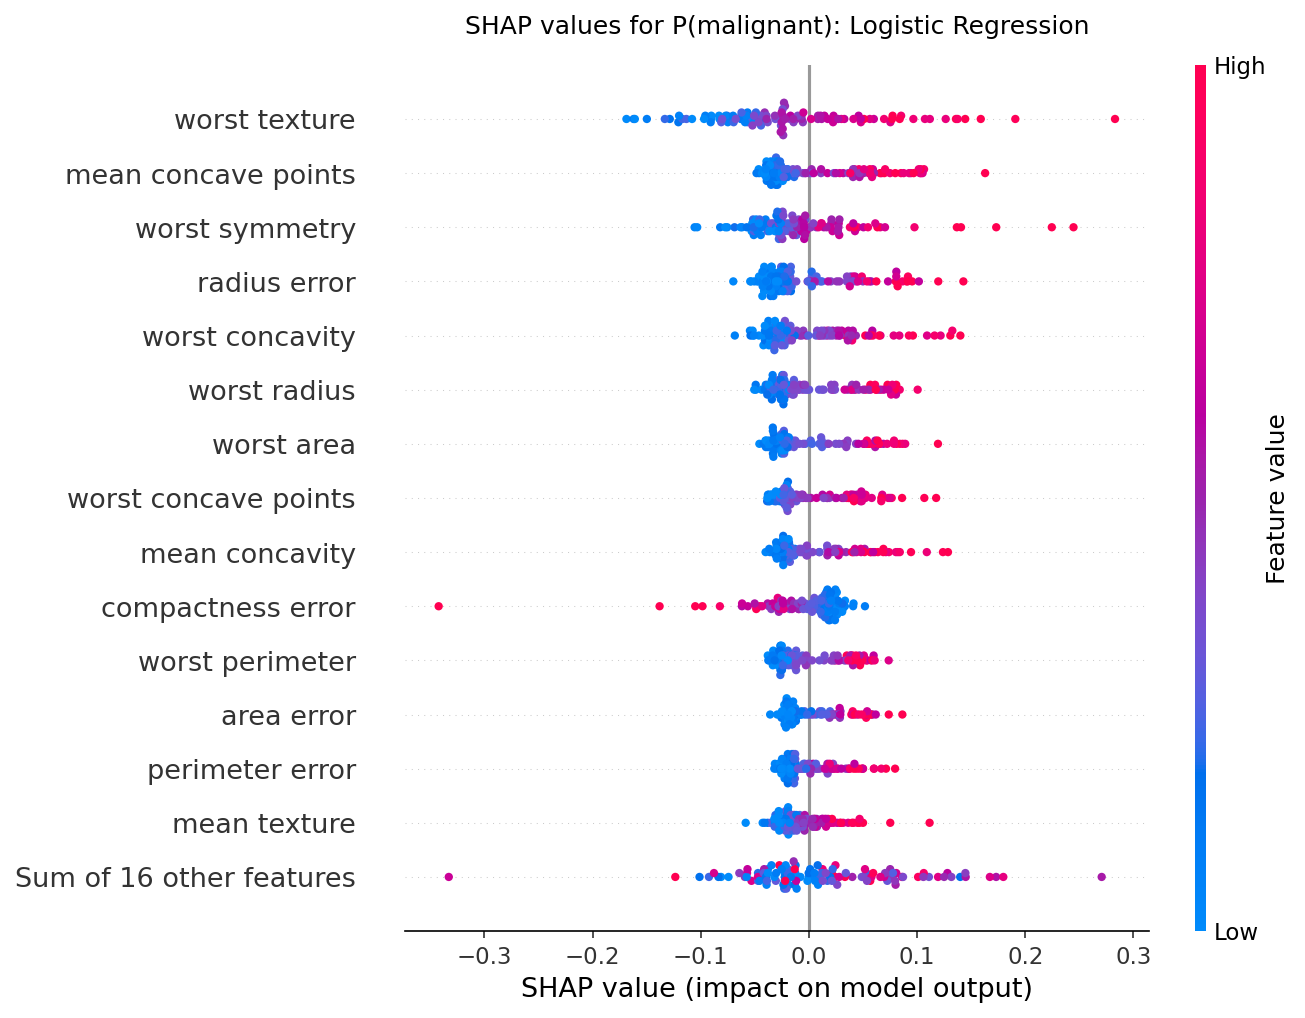

In [10]:
display(Image(FIGURES_DIR / "shap_beeswarm.png", width=700))

Most features behave as expected: larger, more irregular and more concave nuclei push the prediction
toward malignant. **`compactness error` is the exception**: high values push *toward benign*, although its
univariate correlation with malignancy is positive. This is the suppressor effect predicted in notebook 01:
with strongly correlated inputs, the model uses this feature to correct for information already counted by
its correlated neighbours. It is a property of the fitted model, not a biological finding.

The waterfall plot explains a single borderline malignant case, starting from the average prediction
E[f(X)] and adding each feature's contribution until it reaches this patient's predicted probability.

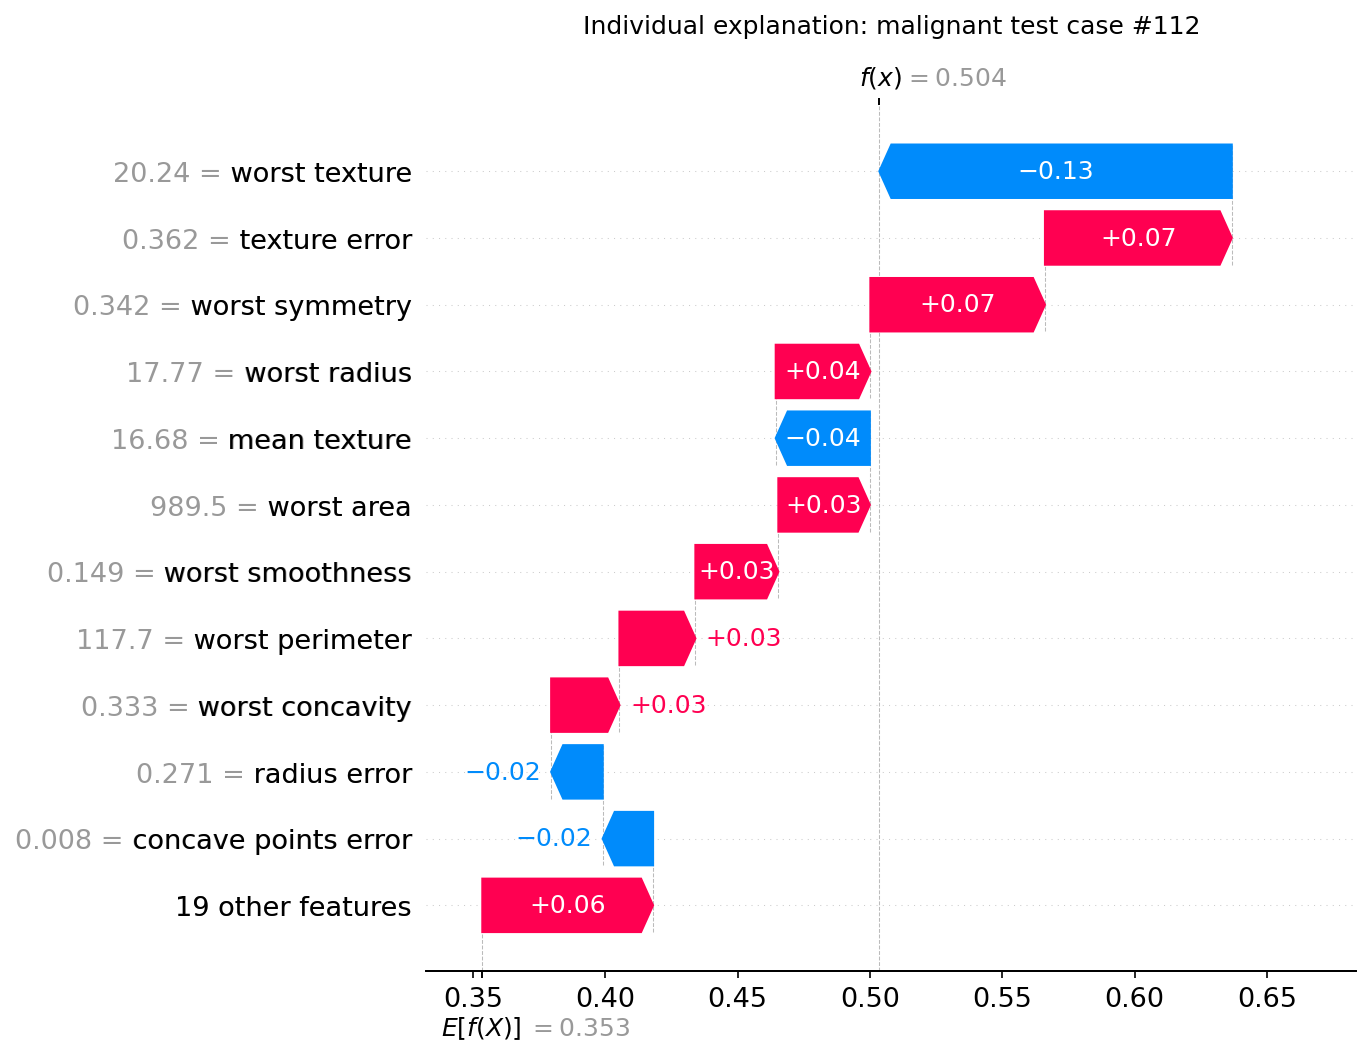

In [11]:
display(Image(FIGURES_DIR / "shap_waterfall.png", width=650))

## Learning curve

The cross-validation AUC still rises slowly with more data while the training AUC decreases slightly. The
gap between them is small (about 0.002 AUC), so there is little overfitting. Additional data of the same
kind would bring only marginal gains on this metric. Larger gains would require **external validation**
on data from another institution, which is the main limitation of this study.

## Limitations

- **Single dataset, single institution.** Performance on other scanners, labs or populations is unknown.
- **Small test set** (114 samples, 42 malignant): wide confidence intervals for sensitivity.
- **Benchmark dataset.** The Wisconsin dataset is curated and almost linearly separable; real-world
  data are noisier.
- **Not a medical device.** This is an educational project and must not be used for diagnosis.

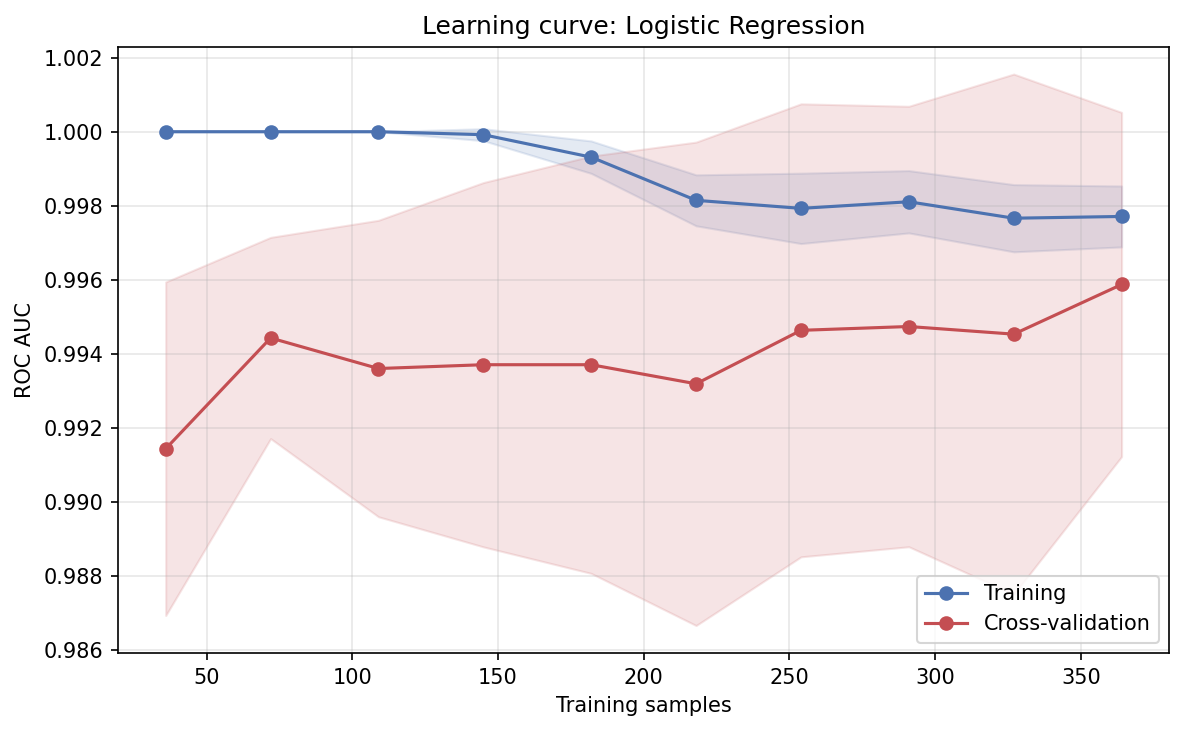

In [12]:
display(Image(FIGURES_DIR / "learning_curve.png", width=600))